# FER-2013 — Model 1: LBP + KNN

This notebook contains Model 1 of the facial-expression detection project.

The hyperparameters below were selected previously using a validation split from the FER-2013 training set. This notebook contains **only the chosen configuration** and can be run from top to bottom.

### Model 1 configuration

- **LBP method:** `nri_uniform`
- **P:** 8
- **R:** 1
- **Spatial grid:** 6 × 6
- **Histogram normalization:** Hellinger
- **Feature dimension:** 2124
- **KNN neighbors:** 9
- **KNN weights:** distance
- **Distance metric:** Euclidean

### FER-2013 test result

- **Accuracy:** 50.68%
- **Macro-F1:** 0.4825
- **Mean full-model latency:** 84.82 ms
- **Median latency:** 84.02 ms

The notebook retrains the model from the complete FER-2013 training set and evaluates it once on the official test set.

## 1. Imports

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

from skimage.feature import local_binary_pattern

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("Imports OK")

Imports OK


## 2. Locate the FER-2013 dataset

This notebook is prepared for the Kaggle dataset **msambare/fer2013**.

Kaggle may mount it under slightly different paths, so the code checks the common locations automatically.

In [2]:
candidate_paths = [
    Path("/kaggle/input/fer2013"),
    Path("/kaggle/input/datasets/msambare/fer2013"),
]

DATASET_PATH = None

for path in candidate_paths:
    if (path / "train").exists() and (path / "test").exists():
        DATASET_PATH = path
        break

if DATASET_PATH is None:
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for train_dir in kaggle_input.rglob("train"):
            candidate = train_dir.parent
            if (candidate / "test").exists():
                DATASET_PATH = candidate
                break

if DATASET_PATH is None:
    raise FileNotFoundError(
        "FER-2013 dataset not found. Add the Kaggle dataset msambare/fer2013."
    )

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

classes = sorted([
    folder.name
    for folder in TRAIN_PATH.iterdir()
    if folder.is_dir()
])

print("Dataset:", DATASET_PATH)
print("Train:", TRAIN_PATH)
print("Test :", TEST_PATH)
print("Classes:", classes)

Dataset: /kaggle/input/datasets/msambare/fer2013
Train: /kaggle/input/datasets/msambare/fer2013/train
Test : /kaggle/input/datasets/msambare/fer2013/test
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Class mapping

The folder names are sorted alphabetically and the same mapping is used consistently for training, testing, prediction, and model export.

In [3]:
class_to_id = {emotion: i for i, emotion in enumerate(classes)}
id_to_class = {i: emotion for emotion, i in class_to_id.items()}

print("Class mapping:")
for i, emotion in enumerate(classes):
    print(f"{i}: {emotion}")

Class mapping:
0: angry
1: disgust
2: fear
3: happy
4: neutral
5: sad
6: surprise


## 4. Load FER-2013 images

All images are converted to grayscale and stored as `uint8` arrays.

Expected sizes for this dataset:

- Training: **28,709** images
- Test: **7,178** images
- Image size: **48 × 48**

In [4]:
def load_dataset_split(split_path):
    images = []
    labels = []

    for label, emotion in enumerate(classes):
        folder = split_path / emotion
        image_names = sorted(os.listdir(folder))

        print(f"Loading {emotion}: {len(image_names)} images")

        for image_name in tqdm(image_names, leave=False):
            image = Image.open(folder / image_name).convert("L")
            image = image.resize((48, 48))
            images.append(np.array(image, dtype=np.uint8))
            labels.append(label)

    return (
        np.stack(images).astype(np.uint8),
        np.array(labels, dtype=np.uint8),
    )


X_train_img, y_train = load_dataset_split(TRAIN_PATH)
X_test_img, y_test = load_dataset_split(TEST_PATH)

print("\nTraining images:", X_train_img.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test_img.shape)
print("Test labels:", y_test.shape)

Loading angry: 3995 images


  0%|          | 0/3995 [00:00<?, ?it/s]

Loading disgust: 436 images


  0%|          | 0/436 [00:00<?, ?it/s]

Loading fear: 4097 images


...

Loading sad: 1247 images


  0%|          | 0/1247 [00:00<?, ?it/s]

Loading surprise: 831 images


  0%|          | 0/831 [00:00<?, ?it/s]


Training images: (28709, 48, 48)
Training labels: (28709,)
Test images: (7178, 48, 48)
Test labels: (7178,)


## 5. Optional visual check

Display one example from each emotion class.

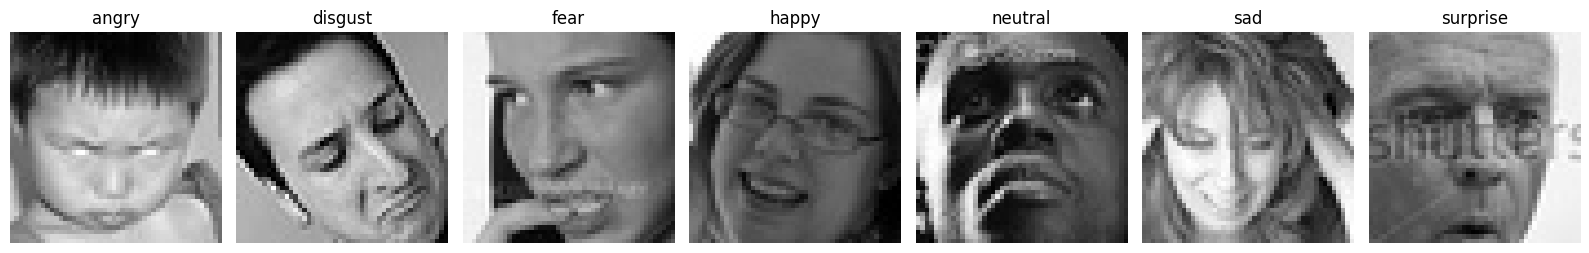

In [5]:
fig, axes = plt.subplots(1, len(classes), figsize=(16, 3))

for label, emotion in enumerate(classes):
    idx = np.where(y_train == label)[0][0]
    axes[label].imshow(X_train_img[idx], cmap="gray")
    axes[label].set_title(emotion)
    axes[label].axis("off")

plt.tight_layout()
plt.show()

## 6. LBP feature extractor

For each 48 × 48 grayscale face:

1. Compute **NRI-uniform LBP** with `P=8` and `R=1`.
2. Divide the LBP image into a **6 × 6 spatial grid**.
3. Build a **59-bin histogram** in each block.
4. Apply **L1 normalization + square root (Hellinger transform)** to each histogram.
5. Concatenate the 36 histograms.

Feature size: **36 × 59 = 2124**.

In [6]:
MODEL1_CONFIG = {
    "lbp_method": "nri_uniform",
    "P": 8,
    "R": 1,
    "grid": 6,
    "normalization": "hellinger",
    "feature_dimension": 2124,
    "k": 9,
    "weights": "distance",
    "metric": "euclidean",
}


def lbp_num_bins(P, method):
    if method == "default":
        return 2 ** P
    if method == "uniform":
        return P + 2
    if method == "nri_uniform":
        return P * (P - 1) + 3
    raise ValueError(f"Unsupported LBP method: {method}")


def extract_model1_lbp_features(image):
    image = np.asarray(image, dtype=np.uint8)

    P = MODEL1_CONFIG["P"]
    R = MODEL1_CONFIG["R"]
    grid = MODEL1_CONFIG["grid"]
    method = MODEL1_CONFIG["lbp_method"]

    lbp = local_binary_pattern(
        image,
        P=P,
        R=R,
        method=method
    )

    n_bins = lbp_num_bins(P, method)

    height, width = lbp.shape
    block_h = height // grid
    block_w = width // grid

    features = []

    for row in range(grid):
        for col in range(grid):
            y1 = row * block_h
            y2 = (row + 1) * block_h
            x1 = col * block_w
            x2 = (col + 1) * block_w

            block = lbp[y1:y2, x1:x2]

            hist = np.bincount(
                block.astype(np.int64).ravel(),
                minlength=n_bins
            ).astype(np.float32)[:n_bins]

            # Hellinger normalization:
            # 1) L1 normalize, 2) square-root transform
            hist /= (hist.sum() + 1e-12)
            hist = np.sqrt(hist)

            features.append(hist)

    feature_vector = np.concatenate(features).astype(np.float32)

    if feature_vector.shape[0] != MODEL1_CONFIG["feature_dimension"]:
        raise ValueError(
            f"Unexpected feature size: {feature_vector.shape[0]}"
        )

    return feature_vector


sample_features = extract_model1_lbp_features(X_train_img[0])

print("Feature vector shape:", sample_features.shape)
print("Expected:", MODEL1_CONFIG["feature_dimension"])

Feature vector shape: (2124,)
Expected: 2124


## 7. Extract features for training and test sets

The output matrices should be:

- Training: `(28709, 2124)`
- Test: `(7178, 2124)`

In [7]:
def build_feature_matrix(images, description="Extracting features"):
    features = []

    print(description)

    for image in tqdm(images):
        features.append(extract_model1_lbp_features(image))

    return np.stack(features).astype(np.float32)


X_train = build_feature_matrix(
    X_train_img,
    "Building FINAL training features..."
)

X_test = build_feature_matrix(
    X_test_img,
    "Building FINAL test features..."
)

print("\nX_train:", X_train.shape, X_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)

Building FINAL training features...


  0%|          | 0/28709 [00:00<?, ?it/s]

Building FINAL test features...


  0%|          | 0/7178 [00:00<?, ?it/s]


X_train: (28709, 2124) float32
X_test : (7178, 2124) float32


## 8. Train the KNN classifier

The KNN configuration is:

- `n_neighbors = 9`
- `weights = "distance"`
- `metric = "euclidean"`
- brute-force neighbor search

In [8]:
model1_knn = KNeighborsClassifier(
    n_neighbors=MODEL1_CONFIG["k"],
    weights=MODEL1_CONFIG["weights"],
    metric=MODEL1_CONFIG["metric"],
    algorithm="brute",
    n_jobs=-1
)

model1_knn.fit(X_train, y_train)

print("Model 1 KNN trained.")
print("K:", model1_knn.n_neighbors)
print("Weights:", model1_knn.weights)
print("Metric:", model1_knn.metric)

Model 1 KNN trained.
K: 9
Weights: distance
Metric: euclidean


## 9. FER-2013 test evaluation

This reports the accuracy, macro-F1, and per-class precision/recall/F1.

In [9]:
y_pred = model1_knn.predict(X_test)

model1_accuracy = accuracy_score(y_test, y_pred)
model1_macro_f1 = f1_score(y_test, y_pred, average="macro")

print("MODEL 1 TEST RESULTS")
print("==================")
print(f"Accuracy : {model1_accuracy:.4f} ({model1_accuracy * 100:.2f}%)")
print(f"Macro F1 : {model1_macro_f1:.4f}")

print("\nClassification report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=classes,
        digits=4
    )
)

MODEL 1 TEST RESULTS
Accuracy : 0.5068 (50.68%)
Macro F1 : 0.4825

Classification report:

              precision    recall  f1-score   support

       angry     0.4544    0.3539    0.3979       958
     disgust     0.5802    0.4234    0.4896       111
        fear     0.4676    0.3457    0.3975      1024
       happy     0.5635    0.7582    0.6465      1774
     neutral     0.4249    0.5045    0.4613      1233
         sad     0.4809    0.2831    0.3564      1247
    surprise     0.5728    0.6955    0.6283       831

    accuracy                         0.5068      7178
   macro avg     0.5063    0.4806    0.4825      7178
weighted avg     0.4984    0.5068    0.4910      7178



## 10. Confusion matrix

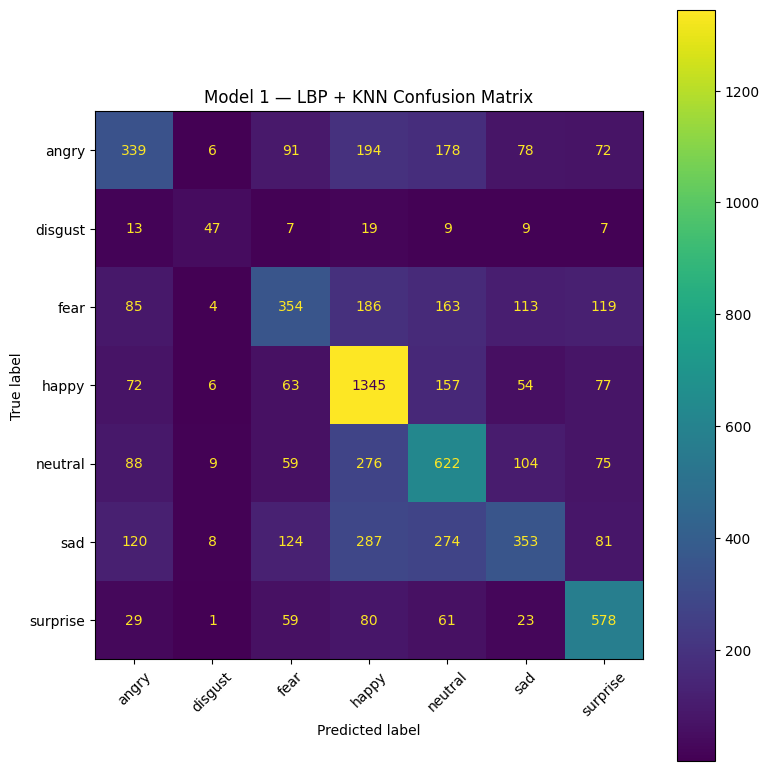

In [10]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Model 1 — LBP + KNN Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Prediction function for the interface

This function can be reused by the team in Gradio or Pygame.

It performs the complete pipeline:

1. Grayscale conversion
2. Resize to 48 × 48
3. LBP feature extraction
4. KNN probability prediction
5. Return emotion, confidence, and latency

Only one KNN neighbor search is performed through `predict_proba()`.

In [11]:
def predict_model1_lbp_knn(image):
    start = time.perf_counter()

    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)

    image = image.convert("L").resize((48, 48))
    image_array = np.array(image, dtype=np.uint8)

    features = extract_model1_lbp_features(
        image_array
    ).reshape(1, -1)

    probabilities = model1_knn.predict_proba(features)

    best_position = int(np.argmax(probabilities[0]))
    predicted_label = int(model1_knn.classes_[best_position])

    emotion = classes[predicted_label]
    confidence = float(probabilities[0, best_position])

    latency_ms = (time.perf_counter() - start) * 1000

    return emotion, confidence, latency_ms


example_idx = 0

emotion, confidence, latency = predict_model1_lbp_knn(
    X_test_img[example_idx]
)

print("True emotion :", classes[int(y_test[example_idx])])
print("Prediction   :", emotion)
print(f"Confidence   : {confidence * 100:.2f}%")
print(f"Latency      : {latency:.2f} ms")

True emotion : angry
Prediction   : happy
Confidence   : 66.33%
Latency      : 82.34 ms


## 12. Latency benchmark

The benchmark uses 50 distinct test images after a short warm-up.

The measured time includes preprocessing, LBP feature extraction, and KNN prediction.

In [12]:
rng = np.random.default_rng(42)

benchmark_indices = rng.choice(
    len(X_test_img),
    size=50,
    replace=False
)

# Warm-up
for idx in benchmark_indices[:5]:
    predict_model1_lbp_knn(X_test_img[idx])

latencies = []

for idx in benchmark_indices:
    _, _, latency = predict_model1_lbp_knn(
        X_test_img[idx]
    )
    latencies.append(latency)

latencies = np.array(latencies)

print("Samples measured:", len(latencies))
print(f"Mean full Model 1 latency: {latencies.mean():.2f} ms")
print(f"Median latency: {np.median(latencies):.2f} ms")
print(f"Minimum latency: {latencies.min():.2f} ms")
print(f"Maximum latency: {latencies.max():.2f} ms")

Samples measured: 50
Mean full Model 1 latency: 79.75 ms
Median latency: 78.89 ms
Minimum latency: 77.37 ms
Maximum latency: 93.90 ms


## 13. Save Model 1

The saved bundle contains:

- trained KNN model
- class order
- complete preprocessing/model configuration
- test metrics

Use this `.pkl` file for the three-model interface.

In [13]:
model1_bundle = {
    "knn": model1_knn,
    "classes": list(classes),
    "config": MODEL1_CONFIG.copy(),
    "test_accuracy": float(model1_accuracy),
    "test_macro_f1": float(model1_macro_f1),
}

MODEL1_PATH = "/kaggle/working/model1_lbp_knn.pkl"

joblib.dump(
    model1_bundle,
    MODEL1_PATH
)

print("Model 1 saved:")
print(MODEL1_PATH)

Model 1 saved:
/kaggle/working/model1_lbp_knn.pkl


## 14. Reload check

This confirms that the exported model can be loaded successfully before sharing it with the group.

In [14]:
loaded_bundle = joblib.load(
    "/kaggle/working/model1_lbp_knn.pkl"
)

print("Model loaded successfully")
print("Classes:", loaded_bundle["classes"])
print("Configuration:", loaded_bundle["config"])
print(
    "Test accuracy:",
    f'{loaded_bundle["test_accuracy"] * 100:.2f}%'
)
print(
    "Test Macro-F1:",
    f'{loaded_bundle["test_macro_f1"]:.4f}'
)

Model loaded successfully
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Configuration: {'lbp_method': 'nri_uniform', 'P': 8, 'R': 1, 'grid': 6, 'normalization': 'hellinger', 'feature_dimension': 2124, 'k': 9, 'weights': 'distance', 'metric': 'euclidean'}
Test accuracy: 50.68%
Test Macro-F1: 0.4825


## 15. Model 1 summary

**Model:** LBP + KNN

**Configuration**

- NRI-uniform LBP
- P = 8
- R = 1
- 6 × 6 spatial grid
- Hellinger-normalized histograms
- 2124-dimensional feature vector
- KNN with K = 9
- Distance-weighted voting
- Euclidean distance

**Results**

- Test accuracy: **50.68%**
- Macro-F1: **0.4825**
- Mean latency: **84.82 ms**
- Median latency: **84.02 ms**

The generated file `model1_lbp_knn.pkl` is the Model 1 file to integrate with the other two facial-expression models.